#Support Vector Machine (SVM) Implementation Notebook

This notebook demonstrates the implementation of Support Vector Machines (SVM)
for classification tasks using the Scikit-Learn library. It covers the following:

1. Data Preparation: Loading and preprocessing a dataset.
2. Model Training: Training an SVM classifier with different kernels.
3. Hyperparameter Tuning: Optimizing hyperparameters like C and gamma.
4. Model Evaluation: Assessing performance using metrics like accuracy and confusion matrix.
5. Visualization: Plotting decision boundaries for better understanding.



#Installing required resources to initiate the Model Training

All libraries imported have a particular usage throughout the pipeline.

Make sure you have them all configured before further execution.



In [1]:
import numpy as np  # Numerical operations and array handling
import pandas as pd  # Data manipulation and analysis
import spacy  # Natural Language Processing (NLP) library
import nltk  # NLP toolkit for tokenization, POS tagging, and more
import gensim.downloader as api  # Pre-trained word embeddings from Gensim
from nltk import word_tokenize, pos_tag  # Tokenization and POS tagging
from sklearn.pipeline import Pipeline  # Creating machine learning pipelines
from sklearn.svm import SVC  # Support Vector Classifier (SVM model)
from sklearn.feature_extraction.text import TfidfVectorizer  # Text vectorization using TF-IDF
from sklearn.preprocessing import LabelEncoder  # Encoding categorical labels
from sklearn.model_selection import train_test_split, GridSearchCV  # Data splitting & hyperparameter tuning
from sklearn.metrics import classification_report  # Model evaluation metrics
import scipy # Import for handling sparse matrices
from scipy.sparse import hstack, csr_matrix  # Handling sparse matrices efficiently
from xgboost import XGBClassifier  # Extreme Gradient Boosting classifier
! pip install datasets  # Install Hugging Face datasets library
from datasets import load_dataset  # Load pre-built datasets from Hugging Face

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 485.4/485.4 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.5/143.5 kB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 kB 19.8 MB/s eta 0:00:00


# Download and load necessary resources

In [2]:
# Load necessary resources
nltk.download('averaged_perceptron_tagger')  # Download POS tagger model for NLTK
nltk.download('punkt')  # Download tokenizer for sentence and word tokenization
nltk.download('punkt_tab')  # Download Punkt Tab tokenizer
nltk.download('averaged_perceptron_tagger_eng')  # Download English POS tagger
nlp = spacy.load("en_core_web_sm")  # Load the small English NLP model from spaCy

[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


# Load the dataset

In [3]:
# Load the dataset
ds = load_dataset("SemEvalWorkshop/sem_eval_2010_task_8")  # Load the SemEval-2010 Task 8 dataset from Hugging Face
df_train = pd.DataFrame(ds["train"])  # Convert the training split into a Pandas DataFrame
df_test = pd.DataFrame(ds["test"])  # Convert the test split into a Pandas DataFrame

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/8.23k [00:00<?, ?B/s]

train-00000-of-00001.parquet:   0%|          | 0.00/673k [00:00<?, ?B/s]

test-00000-of-00001.parquet:   0%|          | 0.00/231k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/8000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2717 [00:00<?, ? examples/s]

# Function to extract dependency-based features and POS Tagging

This function extracts dependency features from a sentence using spaCy. It returns a formatted string where each word is associated with its dependency relation, POS tag and head word.

In [4]:
def get_dependency_features(sentence):
    doc = nlp(sentence)  # Parse the sentence using spaCy
    features = []

    # Loop through the tokens (words) in the sentence
    for token in doc:
        # Feature: word, its POS tag, its dependency relation, and the head word of the token
        features.append(f"{token.text}_{token.pos_}_{token.dep_}_{token.head.text}")

    # Return a string of all the features
    return " ".join(features)

# Apply dependency feature extraction

In [5]:
# Apply dependency feature extraction to the train and test data
df_train['dependency_sentence'] = df_train['sentence'].apply(get_dependency_features)  # Train set
df_test['dependency_sentence'] = df_test['sentence'].apply(get_dependency_features)  # Test set

In [6]:
# Set the target labels for the classification task
y_train = df_train['relation']
y_test = df_test['relation']

# TF-IDF Vectorization

This code applies TF-IDF vectorization to the POS-tagged and dependency-featured sentences from both the training and test datasets. It combines both features and generates a sparse matrix of the term frequencies, with n-grams considered up to bigrams.

In [7]:
# Apply TF-IDF Vectorization on the extracted syntactic features
vectorizer = TfidfVectorizer(lowercase=True, stop_words='english', ngram_range=(1,2))  # Consider unigrams and bigrams
X_train = vectorizer.fit_transform(df_train['dependency_sentence'])  # Train set to numeric format
X_test = vectorizer.transform(df_test['dependency_sentence'])  # Test set to numeric format

# Load GloVe-100 embeddings

This code loads the pre-trained GloVe word embeddings (100-dimensional vectors) from the GloVe wiki-gigaword dataset using Gensim's API.

In [8]:
glove_model = api.load("glove-wiki-gigaword-100")  # Load the pre-trained GloVe word embeddings (100-dimensional vectors)

[==================================================] 100.0% 128.1/128.1MB downloaded


# Function to generate GloVe embeddings

This function generates the GloVe embedding for a sentence by tokenizing it, retrieving the corresponding word vectors, and returning the average of those vectors. If no word vectors are found, it returns a zero vector of length 100.

In [9]:
def get_glove_vector(sentence):
    """
    This function generates a GloVe vector for a given sentence.
    It tokenizes the sentence, looks up the corresponding GloVe vectors for the words,
    and returns the average of the vectors. If a word does not exist in the GloVe model,
    it is ignored.
    """
    words = word_tokenize(sentence)  # Tokenize the sentence into words
    vectors = [glove_model[word] for word in words if word in glove_model]  # Get vectors for words in the sentence
    return sum(vectors) / len(vectors) if vectors else np.zeros(100)  # Return the average vector or a zero vector if no valid words

# Generate GloVe embeddings

In [10]:
X_train_glove = np.vstack(df_train['sentence'].apply(get_glove_vector).values)  # Convert sentences to vectors
X_test_glove = np.vstack(df_test['sentence'].apply(get_glove_vector).values)  # Convert sentences to vectors

# Combine feature sets

This code combines the TF-IDF features and GloVe embeddings into a single feature set for both the training and test datasets. It also prepares the target labels (y_train, y_test) for training and evaluation.

In [11]:
# Combine TF-IDF (sparse) features with GloVe (dense) embeddings into a single feature matrix
X_train_combined = hstack((X_train, X_train_glove))  # Train set: merge sparse TF-IDF and dense GloVe
X_test_combined = hstack((X_test, X_test_glove))  # Test set: merge sparse TF-IDF and dense GloVe

# Print class distribution and Grid Search for Hyperparameter Tuning

This code prints the distribution of classes in the training dataset, defines a parameter grid for hyperparameter tuning using GridSearchCV, and performs a grid search to find the best hyperparameters for a Support Vector Classifier (SVC) model with class balancing.

In [12]:
# Define the parameter grid for hyperparameter tuning
param_grid = {'C': [0.1, 1, 10, 100]}  # Test different values for the regularization parameter C

# Perform grid search again, this time using only the TF-IDF features
grid_search = GridSearchCV(SVC(kernel='linear'), param_grid, cv=5)
grid_search.fit(X_train_combined, y_train)  # Train the grid search model on the TF-IDF feature set

# Output the best parameters from the grid search
print("Best Parameters:", grid_search.best_params_)

/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


Best Parameters: {'C': 10}


# Train optimized SVM model

This code trains an optimized Support Vector Machine (SVM) model using the best hyperparameters found by GridSearchCV. It then makes predictions on the test dataset.

In [13]:
# Train SVM with the combined feature set
svm_model = SVC(kernel='linear', C=grid_search.best_params_['C'])  # Initialize the SVM with a linear kernel
svm_model.fit(X_train_combined, y_train)  # Train the SVM model
predictions_svm = svm_model.predict(X_test_combined)  # Predict the labels for the test set

# Print SVM results

This code prints the classification report for the SVM model, providing detailed evaluation metrics such as precision, recall, F1-score, and support for each class in the test dataset.

In [14]:
print("SVM Classification Report:\n", classification_report(y_test, predictions_svm))
# Print the classification report for the SVM model, including precision, recall, F1-score, and support for each class in the test set

SVM Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.81      0.86       134
           1       0.81      0.88      0.84       194
           2       0.62      0.73      0.67       162
           3       0.65      0.60      0.62       150
           4       0.77      0.87      0.82       153
           5       0.72      0.67      0.69        39
           6       0.81      0.87      0.84       291
           7       0.00      0.00      0.00         1
           8       0.77      0.77      0.77       211
           9       0.80      0.68      0.74        47
          10       0.36      0.18      0.24        22
          11       0.64      0.51      0.57       134
          12       0.63      0.38      0.47        32
          13       0.67      0.89      0.76       201
          14       0.70      0.72      0.71       210
          15       0.76      0.51      0.61        51
          16       0.66      0.56      0.61       108

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# Train XGBoost model for comparison (no tuning for speed)

This code trains an XGBoost classifier with default hyperparameters (without tuning) for comparison purposes. It then makes predictions on the test dataset.

In [15]:
xgb_model = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, verbosity=1)
# Initialize the XGBoost model with 100 estimators, learning rate of 0.1, and max depth of 5 (no hyperparameter tuning for speed)

xgb_model.fit(X_train_combined, y_train)
# Train the XGBoost model on the combined training features and target labels

predictions_xgb = xgb_model.predict(X_test_combined)
# Make predictions on the test set using the trained XGBoost model

# Print XGBoost results

This code prints the classification report for the XGBoost model, providing evaluation metrics such as precision, recall, F1-score, and support for each class in the test dataset.

In [16]:
print("XGBoost Classification Report:\n", classification_report(y_test, predictions_xgb))
# Print the classification report for the XGBoost model, including precision, recall, F1-score, and support for each class in the test set

XGBoost Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.72      0.80       134
           1       0.86      0.79      0.82       194
           2       0.76      0.60      0.67       162
           3       0.60      0.45      0.52       150
           4       0.74      0.71      0.73       153
           5       0.88      0.59      0.71        39
           6       0.76      0.83      0.79       291
           7       0.00      0.00      0.00         1
           8       0.74      0.68      0.71       211
           9       0.83      0.32      0.46        47
          10       0.33      0.14      0.19        22
          11       0.54      0.26      0.35       134
          12       0.60      0.09      0.16        32
          13       0.72      0.73      0.72       201
          14       0.70      0.53      0.60       210
          15       0.84      0.31      0.46        51
          16       0.66      0.44      0.53      

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# Plotting and Visualisation

This code provides visualizations and performance metrics for the trained models. It includes class distribution, confusion matrices, feature importance (for XGBoost), and a word cloud of top TF-IDF features. Additionally, it prints classification reports for both the SVM and XGBoost models.

<ipython-input-17-97cb2840ddd5>:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=y_train, order=y_train.value_counts().index, palette="viridis")


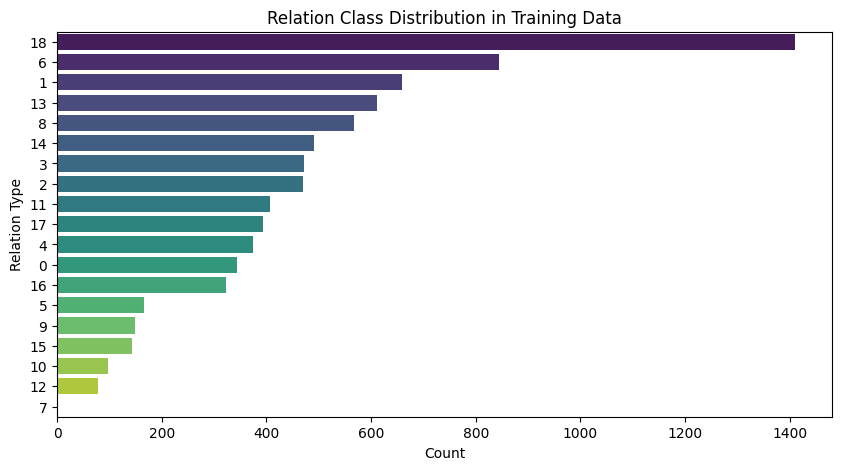

<ipython-input-17-97cb2840ddd5>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=predictions_svm, order=predictions_svm.value_counts().index, palette="viridis")


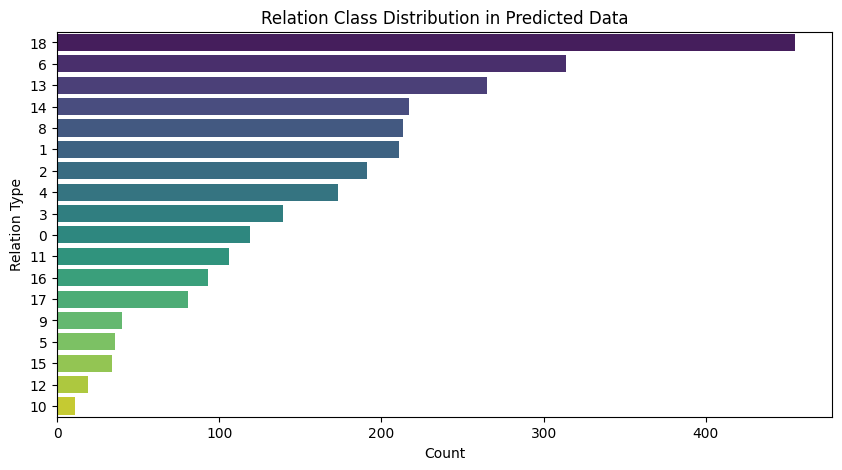

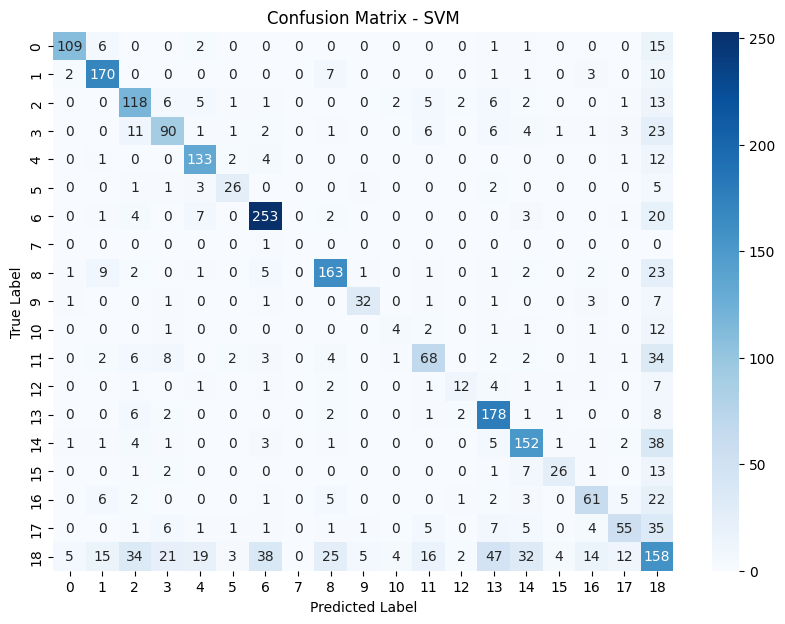

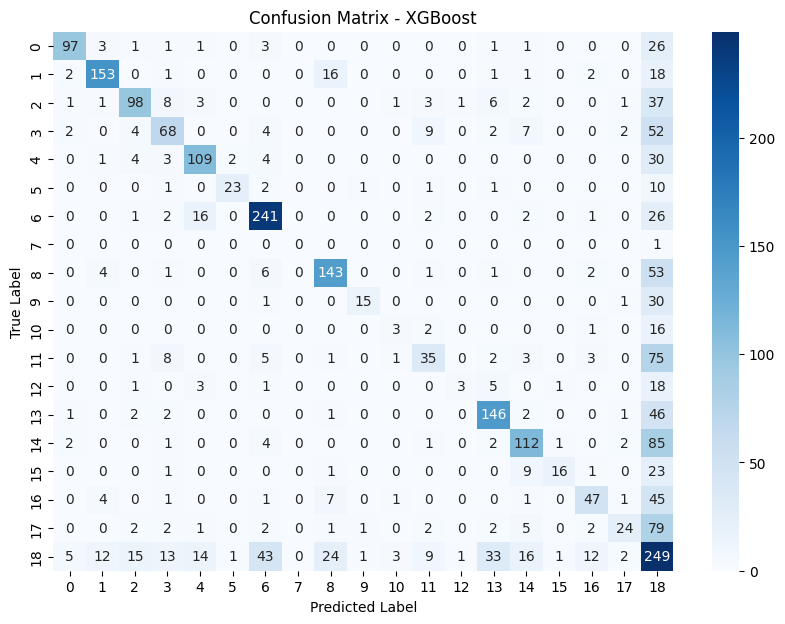


**SVM Classification Report**
              precision    recall  f1-score   support

           0       0.92      0.81      0.86       134
           1       0.81      0.88      0.84       194
           2       0.62      0.73      0.67       162
           3       0.65      0.60      0.62       150
           4       0.77      0.87      0.82       153
           5       0.72      0.67      0.69        39
           6       0.81      0.87      0.84       291
           7       0.00      0.00      0.00         1
           8       0.77      0.77      0.77       211
           9       0.80      0.68      0.74        47
          10       0.36      0.18      0.24        22
          11       0.64      0.51      0.57       134
          12       0.63      0.38      0.47        32
          13       0.67      0.89      0.76       201
          14       0.70      0.72      0.71       210
          15       0.76      0.51      0.61        51
          16       0.66      0.56      0.61       

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/m

In [17]:
import matplotlib.pyplot as plt  # Import for plotting
import seaborn as sns  # Import for advanced statistical visualizations
from sklearn.metrics import confusion_matrix, classification_report  # Import for model evaluation metrics
from wordcloud import WordCloud  # Import for generating word clouds

plt.figure(figsize=(10, 5))
sns.countplot(y=y_train, order=y_train.value_counts().index, palette="viridis")
# Plot the count distribution of relation classes in the training dataset
plt.title("Relation Class Distribution in Training Data")
plt.xlabel("Count")
plt.ylabel("Relation Type")
plt.show()


predictions_svm = pd.Series(predictions_svm)
# Convert the predictions to a Pandas Series for easier handling
plt.figure(figsize=(10, 5))
sns.countplot(y=predictions_svm, order=predictions_svm.value_counts().index, palette="viridis")
# Plot the count distribution of relation classes in the Predicted labels trained in the SVM model
plt.title("Relation Class Distribution in Predicted Data")
plt.xlabel("Count")
plt.ylabel("Relation Type")
plt.show()

# Confusion Matrix Function
def plot_confusion_matrix(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)
    # Calculate confusion matrix for the given true and predicted labels
    plt.figure(figsize=(10, 7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=np.unique(y_true), yticklabels=np.unique(y_true))
    # Plot confusion matrix using heatmap for better visualization
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.show()

plot_confusion_matrix(y_test, predictions_svm, "SVM")
# Plot confusion matrix for the SVM model

plot_confusion_matrix(y_test, predictions_xgb, "XGBoost")
# Plot confusion matrix for the XGBoost model

print("\n**SVM Classification Report**")
print(classification_report(y_test, predictions_svm))
# Print the detailed classification report for the SVM model

print("\n**XGBoost Classification Report**")
print(classification_report(y_test, predictions_xgb))
# Print the detailed classification report for the XGBoost model

# Saving the Model

This code saves the trained SVM and XGBoost models, and the TF-IDF vectorizer into separate files using joblib. It ensures that these objects can be loaded later for predictions or further analysis.

In [18]:
import joblib  # Import joblib for saving and loading models and objects

joblib.dump(svm_model, "svm_model.pkl")
# Save the trained SVM model to a file

joblib.dump(xgb_model, "xgb_model.pkl")
# Save the trained XGBoost model to a file

joblib.dump(vectorizer, "tfidf_vectorizer.pkl")
# Save the TF-IDF vectorizer to a file

print("Models, vectorizer saved successfully!")

Models, vectorizer saved successfully!


# Testing the model on a sample Sentence

This code tests the trained SVM and XGBoost models on a new sample sentence. It extracts linguistic features (POS tags and dependency features), transforms them into TF-IDF vectors, ensures the correct feature shape, and then predicts the relation type using both models.

In [19]:
# Load saved models and vectorizer
svm_model = joblib.load("svm_model.pkl")  # Load the trained SVM model
xgb_model = joblib.load("xgb_model.pkl")  # Load the trained XGBoost model
vectorizer = joblib.load("tfidf_vectorizer.pkl")  # Load the TF-IDF vectorizer

def combine_features(tfidf_features, glove_vector):
    """
    This function combines sparse TF-IDF features with a dense GloVe vector into a single feature vector.
    """

    # Combine the sparse TF-IDF features with the sparse GloVe vector
    X_input_combined = hstack((tfidf_features, glove_vector.reshape(1, -1))) # This stacks them horizontally
    return X_input_combined

def predict_relation(sentence):
    dep_features = get_dependency_features(sentence)  # Extract dependency features

    # Convert sentence to TF-IDF features
    tfidf_features = vectorizer.transform([dep_features])

    glove_vector = get_glove_vector(sentence)

    combined_features = combine_features(tfidf_features, glove_vector)

    # Use the SVM model to predict the relation
    prediction_svm = svm_model.predict(combined_features)

    # Predict using XGBoost
    prediction_xgb = xgb_model.predict(combined_features)

    return {
        "SVM Prediction": prediction_svm[0],  # Return SVM predicted relation
        "XGBoost Prediction": prediction_xgb[0]  # Return XGBoost predicted relation
    }

# Example Usage
new_sentence = "The <e1>singer</e1>, who performed three of the nominated songs, also caused a <e2>commotion</e2> on the red carpet."
result = predict_relation(new_sentence)

print("Prediction Results:", result)

Prediction Results: {'SVM Prediction': 0, 'XGBoost Prediction': 0}
